# Taller de Aprendizaje No Supervisado
## Parte 1: Dataset de Setas (variables categóricas)

### Mushroom Dataset

Podéis obtener el conjunto de datos en el siguiente enlace:

[Mushroom Dataset](https://www.kaggle.com/uciml/mushroom-classification)

Como podréis comprobar, hay **muchas variables, todas categóricas**, por lo que las exploraciones con *scatterplot* no nos serán útiles como en otros casos.

La variable a predecir es `class` (`e` = comestible / *edible*, `p` = venenosa / *poisonous*) y es **binaria**.

> En este taller usaremos las etiquetas **solo para validar** lo que descubre el clustering. La idea del aprendizaje no supervisado es encontrar estructura *sin* mirar la etiqueta.

### Algoritmos que cubriremos

**Reducción de dimensionalidad:** PCA (lineal) y t-SNE (no lineal).

**Clustering:** K-Means, Clustering Jerárquico (Aglomerativo), Gaussian Mixture Models (GMM) y DBSCAN.

**Evaluación:** método del codo, *silhouette*, Davies-Bouldin, Calinski-Harabasz y (como tenemos etiqueta) Adjusted Rand Index y NMI.

**Detección de anomalías:** Isolation Forest.

In [2]:
%matplotlib inline
# Hace que los gráficos aparezcan dentro del notebook, justo debajo de la celda que los crea.
import warnings
warnings.filterwarnings("ignore")  # oculta avisos (FutureWarning, etc.) para que la salida quede limpia en clase

# Tablas y cálculo numérico
import pandas as pd      # DataFrame: la "hoja de cálculo" con la que trabajamos
import numpy as np       # arrays y operaciones matemáticas rápidas
# Gráficos
import seaborn as sns            # gráficos estadísticos bonitos con poco código
import matplotlib.pyplot as plt  # base de todos los gráficos (títulos, ejes, plt.show())
# Preparación de datos y reducción de dimensiones
from sklearn.model_selection import train_test_split  # separa datos en entrenamiento y examen
from sklearn.decomposition import PCA                 # reducción de dimensiones lineal
# Algoritmos de clustering
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.manifold import TSNE                     # reducción de dimensiones no lineal (solo para visualizar)
from sklearn.mixture import GaussianMixture          # GMM: clusters como "nubes" probabilísticas
# Modelos supervisado y de anomalías
from sklearn.ensemble import RandomForestClassifier, IsolationForest
# Métricas para evaluar los clusters (3 internas + 2 que usan la etiqueta: ARI y NMI)
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
# Para dibujar el dendrograma
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style='whitegrid')  # estilo visual de todos los gráficos: fondo blanco con rejilla
RANDOM_STATE = 42 

### Leer conjunto de datos y primer vistazo

In [3]:
## Lee el archivo CSV y lo guarda en una tabla (DataFrame) llamada df.
# Cada fila es una seta; cada columna, una característica.
df = pd.read_csv('data/mushrooms.csv')
# head() muestra solo las 5 primeras filas, para echar un vistazo sin imprimir 8.000 filas.
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


### Exploración de datos

In [13]:
# Descripcion del conjunto de datos, estandar.
# df.shape devuelve (número de filas, número de columnas).
print("Filas y columnas:", df.shape)
# describe() resume cada columna. Con texto devuelve: count (datos), unique (categorías distintas),
# top (la categoría más común) y freq (cuántas veces aparece la más común).
df.describe()

Filas y columnas: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,...,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,2,6,4,10,2,9,2,2,2,12,...,4,9,9,1,4,3,5,9,6,7
top,e,x,y,n,f,n,f,c,b,b,...,s,w,w,p,w,o,p,w,v,d
freq,4208,3656,3244,2284,4748,3528,7914,6812,5612,1728,...,4936,4464,4384,8124,7924,7488,3968,2388,4040,3148


In [14]:
# Informacion sobre el tipo de datos de cada feature.
# info() lista cada columna con su tipo de dato y cuántos valores no nulos tiene.
# Aquí todo es texto (object/str): confirma que no hay ninguna variable numérica.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

#### Calcular el número de nulos de cada feature

In [15]:
# Igual que otras veces, una linea: contar los nulos por variable.
# isnull() devuelve True en cada casilla vacía (NaN); sum() cuenta los True por columna.
# Todo da 0, pero eso NO descarta nulos disfrazados (como el '?' que veremos enseguida).
df.isnull().sum()

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

#### Buscar valores extraños. Para ello, ver los valores únicos en cada feature

In [16]:
# Obtener un nuevo dataframe: en una columna las features (feature)
# y en la otra el numero de valores unicos asociados (n_values).
# n_values = ...
columns = df.columns                                     # lista con los nombres de todas las columnas
n_values = [df[a].unique() for a in df.columns]          # para cada columna, sus valores distintos (unique)
                                                         # (es una "lista por comprensión": un bucle for en una línea)
counts = pd.DataFrame()                                  # tabla vacía donde iremos añadiendo columnas
counts['features'] = columns                             # 1a columna: el nombre de la variable
counts['n_values'] = n_values                            # 2a columna: los valores distintos que tiene (aquí se ve el '?')
counts['n_unique'] = [len(v) for v in n_values]          # 3a columna: cuántos valores distintos son (len = longitud de la lista)
counts                                                   # mostramos la tabla: busquen 'veil-type' (1 valor) y 'stalk-root' (con '?')

,features,n_values,n_unique
0,class,"[p, e]",2
1,cap-shape,"[x, b, s, f, k, c]",6
2,cap-surface,"[s, y, f, g]",4
3,cap-color,"[n, y, w, g, e, p, b, u, c, r]",10
4,bruises,"[t, f]",2
5,odor,"[p, a, l, n, f, c, y, s, m]",9
6,gill-attachment,"[f, a]",2
7,gill-spacing,"[c, w]",2
8,gill-size,"[n, b]",2
9,gill-color,"[k, n, g, p, w, h, u, e, b, r, y, o]",12


Observad dos cosas:
- `veil-type` tiene **un único valor** → no aporta información.
- `stalk-root` contiene el valor `'?'`, que en realidad es un **valor desconocido (nulo encubierto)**.

#### Tratar aquellos valores que entendamos que sean nulos

In [17]:
# Imputaciones. Podeis quitar esos puntos (fila entera), imputar con la moda
# o dejar ese valor como una posibilidad mas. Aqui imputamos '?' con la moda.
# (df['stalk-root'] == '?') da True/False por fila; sum() cuenta los True, o sea, cuántas setas tienen '?'.
print("Setas con '?' en stalk-root:", (df['stalk-root'] == '?').sum())

# Moda calculada SOLO con los valores conocidos
# df.loc[condición, columna] filtra las filas que cumplen la condición (!= '?') y se queda con esa columna.
# mode() devuelve los valores más frecuentes; [0] toma el primero.
mode_value = df.loc[df['stalk-root'] != '?', 'stalk-root'].mode()[0]
print("Moda de stalk-root:", mode_value)

# replace('?', mode_value) cambia cada '?' por la moda y guardamos el resultado en la misma columna.
df['stalk-root'] = df['stalk-root'].replace('?', mode_value)
# Comprobación: ahora debe dar 0.
print("Quedan '?':", (df['stalk-root'] == '?').sum())

Setas con '?' en stalk-root: 2480
Moda de stalk-root: b
Quedan '?': 0


#### ¿Todas las features aportan información? Si alguna no aporta, eliminadla

In [18]:
# Dejar por el camino las features con un solo valor (no aportan nada).
# Para cada columna c, nunique() cuenta sus valores distintos; si es 1, la columna es constante.
# El resultado es una lista con los nombres de esas columnas (aquí solo veil-type).
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Columnas constantes:", constant_cols)
# drop(columns=...) elimina esas columnas y devolvemos el resultado a df.
df = df.drop(columns=constant_cols)
df.shape   # una columna menos que antes

Columnas constantes: ['veil-type']


(8124, 22)

#### Separar entre variables predictoras y variable a predecir

In [19]:
# La variable a predecir es 'class'.
# y =
# X =
y = df['class']                      # 'e' / 'p'  (el sobre cerrado): la etiqueta que NO usará el clustering
y_bin = (y == 'p').astype(int)       # 1 = venenosa, 0 = comestible: (y == 'p') da True/False y astype(int) lo pasa a 1/0
X = df.drop(columns='class')         # lo que ve la recolectora: todas las columnas menos la etiqueta
print(y.value_counts())              # cuántas setas hay de cada clase (casi mitad y mitad: dataset equilibrado)

class
e    4208
p    3916
Name: count, dtype: int64


#### Codificar correctamente las variables categóricas a numéricas

In [20]:
# One Hot Encoder (una linea). Pista: pd.get_dummies
# get_dummies crea una columna 0/1 por cada categoría de cada variable (One-Hot).
# dtype=int fuerza que sea 0/1 en lugar de False/True.
X = pd.get_dummies(X, dtype=int)
print("Forma tras One-Hot:", X.shape)   # pasamos de 21 columnas de texto a 115 columnas numéricas
X.head()

Forma tras One-Hot: (8124, 115)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


#### Train / test split

In [21]:
# Os lo dejamos a todos igual
# random_state=42 hace que la partición sea la misma para todos.
# Devuelve 4 objetos: X de train/test e y de train/test.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)
print(X_train.shape, X_test.shape)

(5443, 115) (2681, 115)


## PCA

Es un conjunto de datos del que aún no hemos visto gráficas, así que vamos a hacer algunas. Tenemos muchas variables, **PCA al rescate**: le pedimos dos dimensiones y las pintamos. Serán **las que retengan más información (varianza)**.

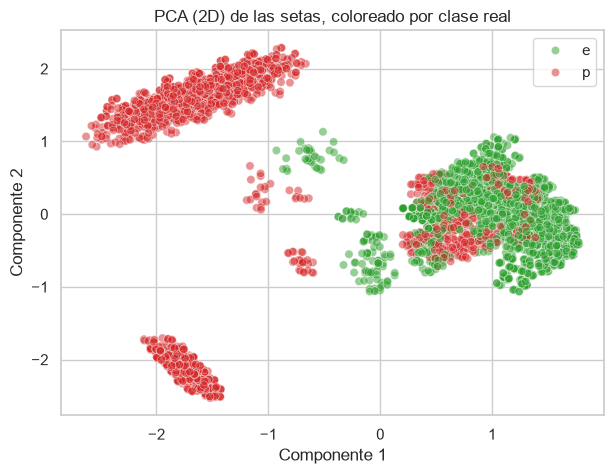

Varianza explicada por los 2 ejes: [0.169 0.127] = 0.296


In [22]:
# metodo de sklearn


# Representar en un scatterplot y poner en color las etiquetas de entrenamiento
pca = PCA(n_components=2, random_state=RANDOM_STATE)   # PCA que se quedará con las 2 mejores direcciones
pca.fit(X_train)                                       # aprende los ejes mirando SOLO los datos de entrenamiento (sin etiqueta)
Z = pca.transform(X_train)                             # proyecta cada seta a esas 2 coordenadas: Z[:, 0] y Z[:, 1]

plt.figure(figsize=(7, 5))                             # crea un lienzo de 7x5 pulgadas
# Scatter: eje x = componente 1, eje y = componente 2. hue colorea por clase real (solo para decorar, PCA no la vio).
# alpha=0.5 hace los puntos semitransparentes para ver dónde se acumulan; palette fija verde=comestible, rojo=venenosa.
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y_train.values, alpha=0.5, palette={'e': 'tab:green', 'p': 'tab:red'})
plt.xlabel('Componente 1'); plt.ylabel('Componente 2')
plt.title('PCA (2D) de las setas, coloreado por clase real')
plt.show()
# explained_variance_ratio_ = fracción de información que guarda cada eje; la suma es lo que conservamos en total.
print("Varianza explicada por los 2 ejes:", pca.explained_variance_ratio_.round(3), "=", pca.explained_variance_ratio_.sum().round(3))

Parece que está bastante separadito, ¡a ojo mucho se puede ver! :)

Antes de seguir, entrenamos un clasificador supervisado como **línea base** (así sabemos cuánta información hay realmente en los datos).

In [23]:
# 1. Definir el clasificador y el numero de estimadores
# 2. Entrenar en train
# 3. Calcular la precision sobre test
# Random Forest = 100 árboles de decisión que votan. n_estimators es el número de árboles.
rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)    # aprende CON etiqueta: relaciona las características con 'e'/'p'
# score() predice las setas de test y devuelve la proporción de aciertos (1.0 = 100%).
print("Precisión en test (115 features):", rf.score(X_test, y_test))

Precisión en test (115 features): 1.0


Es un conjunto sencillo y Random Forest es muy bueno. Veamos cuántas features tenemos:

In [24]:
# Número de filas y de columnas del conjunto de entrenamiento (115 columnas).
X_train.shape

(5443, 115)

¿Muchas features, no? Vamos a reducirlas con PCA y ver cuántas componentes necesita Random Forest para mantener su precisión.

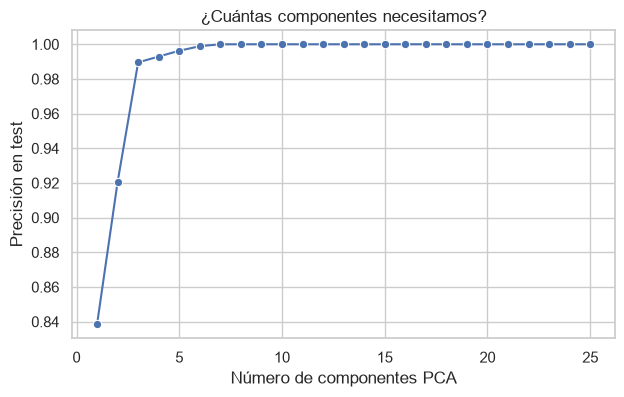

{1: 0.8385, 2: 0.9206, 3: 0.9896, 5: 0.9963, 10: 1.0}


In [25]:
n_features = range(1, 26)   # probaremos con 1, 2, 3 ... 25 componentes
scores = []                 # aquí guardaremos la precisión de cada prueba

for n in n_features:
    # 1) PCA con n componentes, ajustado SOLO con train (para no filtrar información del examen)
    p = PCA(n_components=n, random_state=RANDOM_STATE).fit(X_train)
    # 2) Un Random Forest nuevo, entrenado con los datos ya reducidos a n columnas
    rf_n = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
    rf_n.fit(p.transform(X_train), y_train)
    # 3) A test solo se le aplica transform (con los ejes aprendidos en train) y guardamos la precisión
    scores.append(rf_n.score(p.transform(X_test), y_test))

plt.figure(figsize=(7, 4))
sns.lineplot(x=list(n_features), y=scores, marker='o')     # curva: nº de componentes frente a precisión
plt.xlabel('Número de componentes PCA'); plt.ylabel('Precisión en test')
plt.title('¿Cuántas componentes necesitamos?')
plt.show()
# Diccionario con los valores de algunos puntos clave, para leerlos sin adivinar sobre el gráfico.
print({n: round(s, 4) for n, s in zip(n_features, scores) if n in (1, 2, 3, 5, 10)})

A partir de ~10 componentes ya tenemos la precisión que queríamos, reduciendo las variables a una fracción de las originales.

---
## t-SNE: reducción **no lineal** para visualizar

PCA es lineal. **t-SNE** intenta preservar la vecindad local y suele separar mejor los grupos visualmente. Es más caro, así que lo calculamos sobre una **muestra**.

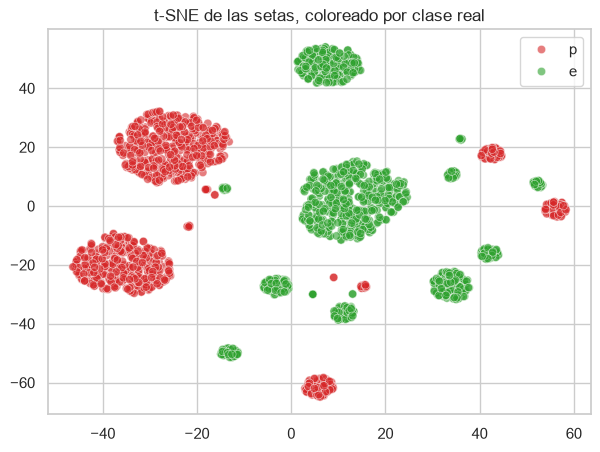

In [26]:
# 1. Tomar una muestra de X_train (t-SNE es lento)
# 2. Definir TSNE(n_components=2, ...) y ajustar
# 3. Pintar el embedding coloreado por la etiqueta
# t-SNE es lento, así que trabajamos con una muestra aleatoria de 2000 setas de train.
sample = X_train.sample(2000, random_state=RANDOM_STATE)
y_sample = y_train.loc[sample.index]     # sus etiquetas (solo para colorear): .loc busca por el mismo índice

# perplexity=30: cuántos vecinos mira cada punto. init='pca': arranca desde una proyección PCA (más estable).
tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=RANDOM_STATE)
emb = tsne.fit_transform(sample)         # calcula las 2 coordenadas de cada seta de la muestra

plt.figure(figsize=(7, 5))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=y_sample.values, alpha=0.6, palette={'e': 'tab:green', 'p': 'tab:red'})
plt.title('t-SNE de las setas, coloreado por clase real')
plt.show()

---
## Clustering

El conjunto es sencillito, así que probemos clustering para ver qué información obtenemos **sin usar las etiquetas**. Trabajaremos sobre una representación reducida con PCA (10 componentes), que limpia ruido y acelera los algoritmos.

In [ ]:
# Reducir X (one-hot completo) a 10 componentes con PCA -> X_red

### K-Means: ¿cuántos clusters? Codo + Silhouette

El **método del codo** mira la inercia (suma de distancias a los centroides). El **coeficiente de silhouette** mide cómo de bien separados están los clusters (cuanto más alto, mejor). Usamos ambos.

In [ ]:
from sklearn.cluster import KMeans

k_values = # definir un rango
inercias, silhouettes = [], []
for k in k_values:
    # Definir KMeans y ajustar sobre X_red
    # Guardar la inercia (km.inertia_) y el silhouette_score

# Pintar las dos curvas (codo y silhouette)

### K-Means final y comparación con la etiqueta

Sabemos que hay dos clases (comestible / venenosa), así que probamos `k=2`. Con `catplot` vemos la distribución de la etiqueta real dentro de cada cluster.

In [ ]:
# Aprender KMeans con el k obtenido y preparar el catplot.
kmeans = # Definir y entrenar KMeans

# ax = sns.catplot(col=, x=, data=, kind='count', col_wrap=4)
# Calcular ARI y NMI frente a y_bin

> **ARI / NMI** comparan los clusters con la etiqueta real (0 = aleatorio, 1 = idéntico). Sin haber visto la etiqueta, K-Means recupera buena parte de la estructura comestible/venenosa, pero **no es perfecto**: ese es el reto real del no supervisado.

### Comparativa de algoritmos de clustering

Vamos a poner a competir **K-Means, Aglomerativo, GMM y DBSCAN** con varias métricas. Las tres primeras métricas son *internas* (no usan etiqueta); ARI sí la usa, para validar.

In [ ]:
# Definir una funcion evaluar(nombre, labels, X) que devuelva silhouette,
# davies_bouldin, calinski_harabasz y ARI.
# Aplicarla a KMeans, AgglomerativeClustering, GaussianMixture y DBSCAN
# y montar una tabla (DataFrame) comparativa.

### Dendrograma (clustering jerárquico)

El clustering aglomerativo construye una jerarquía que podemos visualizar como **dendrograma**. La altura a la que se unen dos grupos indica cómo de distintos son. Lo calculamos sobre una muestra para que se lea bien.

In [ ]:
# 1. Tomar una muestra de X_red
# 2. linkage(..., method='ward')
# 3. dendrogram(...) para visualizar la jerarquia

### DBSCAN: la **métrica de distancia importa**

DBSCAN agrupa por densidad. Pero con datos **categóricos** codificados en one-hot, la distancia euclídea no captura bien la similitud. Comparemos euclídea (sobre PCA) con la distancia de **Jaccard** (pensada para datos binarios).

In [ ]:
# Comparar DBSCAN con metric='euclidean' (sobre X_red) y metric='jaccard'
# (sobre el one-hot binario). Observar cual recupera mejor la estructura (ARI).

> **Lección:** con datos categóricos, elegir la distancia adecuada (Jaccard/Hamming) puede cambiar por completo el resultado de un algoritmo basado en densidad. No hay un algoritmo que gane siempre: depende del tipo de datos.

### Visualización final: clusters vs etiqueta real

Repetimos el scatter PCA, pero coloreando por el cluster de K-Means y por la etiqueta real, lado a lado.

In [ ]:
# Entrenar PCA(2) sobre X para representar.
# Pintar dos scatter: uno coloreado por el cluster de KMeans y otro por la etiqueta real.

Es bastante parecido, ¿no? No es tan bueno como Random Forest (que usa etiquetas), pero K-Means ha identificado bastante bien la estructura **sin usarlas**. Si no tuviéramos etiquetas, esta aproximación nos ayudaría mucho a clasificar los tipos de hongos.

---
## Detección de anomalías (Isolation Forest)

Una tarea no supervisada distinta: encontrar las muestras **atípicas**. Isolation Forest aísla los puntos raros con pocos cortes aleatorios.

In [ ]:
# 1. Definir IsolationForest(contamination=...) y ajustar sobre X_red
# 2. predict -> -1 son anomalias
# 3. Pintarlas sobre la proyeccion PCA

---
## Para ir más allá (opcional)

- **UMAP** (`pip install umap-learn`): alternativa a t-SNE, más rápida y preserva mejor la estructura global.
- **HDBSCAN** (`pip install hdbscan`): DBSCAN jerárquico que no necesita fijar `eps`.
- **Reglas de asociación** (`mlxtend`, Apriori/FP-Growth): muy naturales aquí por ser datos categóricos; permiten descubrir reglas tipo «si olor = X entonces venenosa».

## Conclusiones

- PCA y t-SNE nos dejaron *ver* un dataset de >100 dimensiones.
- K-Means, GMM y Aglomerativo recuperan la estructura comestible/venenosa con ARI ~0.6 **sin usar la etiqueta**.
- DBSCAN nos enseñó que **la métrica de distancia importa** con datos categóricos.
- Isolation Forest localiza las setas más atípicas.
- El no supervisado no da una respuesta «perfecta», pero descubre estructura muy útil cuando no tenemos etiquetas.